# Kalman dynamic hedge ratios on daily data (extension)

Presentation only: the tests are in `code/kalman_hedge.py`, the data loader and market proxy in
`code/kalman_data.py`, and the runs in `code/kalman_runs.py`. The pre-registration is
`results/kalman/PREREG.md`. Holdout from 2019-12-01. The Compustat runs hedge against a
**25-name cap-weighted leave-one-out proxy, not the STI**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'code'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import kalman_hedge as kh
from kalman_data import load_compustat, PROXY_LABEL

RES = Path('..') / 'results' / 'kalman'
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False})
print(PROXY_LABEL)

25-name cap-weighted LOO proxy, not the STI


## Tests counted and the Bonferroni bar

In [2]:
print((RES / 'test_count.txt').read_text())

Tests counted over the daily runs only (PREREG.md):
daily_25_proxy: 75 hedge DM tests (25 targets x 3)
daily_25_proxy_weekly: 75 hedge DM tests (25 targets x 3)
daily_25_proxy: 133 pair x method x entry OOS tests (156 combinations, 23 never traded)
daily_25_proxy: 12 pairs portfolio OOS tests (method x entry)
total: 295
Bonferroni: p < 0.05 / 295 = 0.000169, two-sided |t| > 3.76
market series: 25-name cap-weighted LOO proxy, not the STI



## Hedge effectiveness by frequency

Mean out-of-sample hedge effectiveness (1 minus hedged over unhedged variance) across single
names. The two middle rows change the universe and then the market series while staying
monthly, so the last two rows can be read as the effect of frequency alone.

In [3]:
summary = pd.read_csv(RES / 'hedge_summary.csv', index_col=0)
summary

,Static OLS,Rolling,EWMA,Kalman,EW book Kalman,EW book Rolling,names,median n_oos,market
monthly_30_sti,0.2841,0.3145,0.3113,0.3073,0.8303,0.8352,27,74.0,STI price index
monthly_25_sti,0.3205,0.3378,0.3365,0.3331,0.8108,0.8137,22,74.0,STI price index
monthly_25_proxy,0.2799,0.2917,0.2929,0.2873,0.8588,0.8575,22,80.0,"25-name cap-weighted LOO proxy, not the STI"
daily_25_proxy,0.3005,0.3238,0.3336,0.3314,0.8632,0.8583,24,1594.0,"25-name cap-weighted LOO proxy, not the STI"
daily_25_proxy_weekly,0.3005,0.3200,0.3301,0.3287,0.8611,0.8576,24,1594.0,"25-name cap-weighted LOO proxy, not the STI"


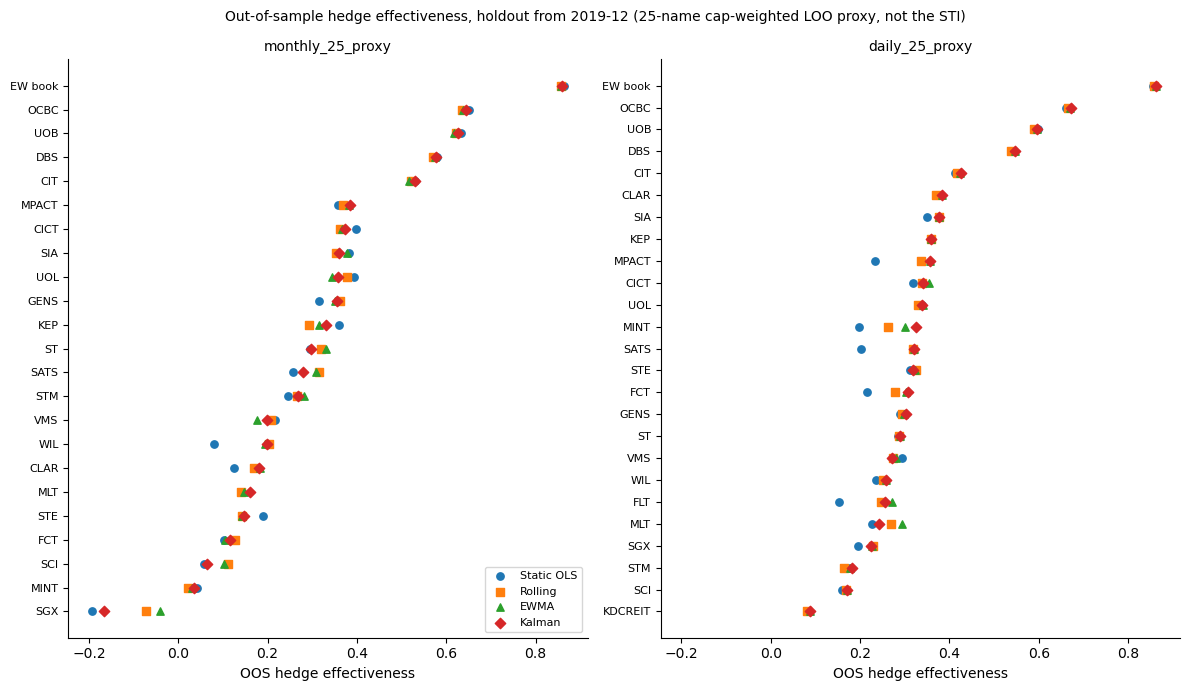

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True)
methods = ['Static OLS', 'Rolling', 'EWMA', 'Kalman']
marks = dict(zip(methods, ['o', 's', '^', 'D']))
for ax, tag in zip(axes, ['monthly_25_proxy', 'daily_25_proxy']):
    h = pd.read_csv(RES / f'hedge_{tag}.csv', index_col=0).drop(columns='market')
    h = h.sort_values('Kalman')
    y = np.arange(len(h))
    for m in methods:
        ax.scatter(h[m], y, marker=marks[m], s=28, label=m)
    ax.set_yticks(y); ax.set_yticklabels(h.index, fontsize=8)
    ax.set_title(f'{tag}', fontsize=10); ax.set_xlabel('OOS hedge effectiveness')
axes[0].legend(loc='lower right', fontsize=8)
fig.suptitle(f'Out-of-sample hedge effectiveness, holdout from 2019-12 ({PROXY_LABEL})', fontsize=10)
fig.tight_layout(); fig.savefig(RES / 'fig_hedge_effectiveness.png'); plt.show()

## Beta paths for WIL and DBS (daily)

Hedge ratios against the leave-one-out proxy. WIL had the most unstable beta in the monthly
study; DBS is a stable large bank for contrast. Recomputed here from the same code and data.

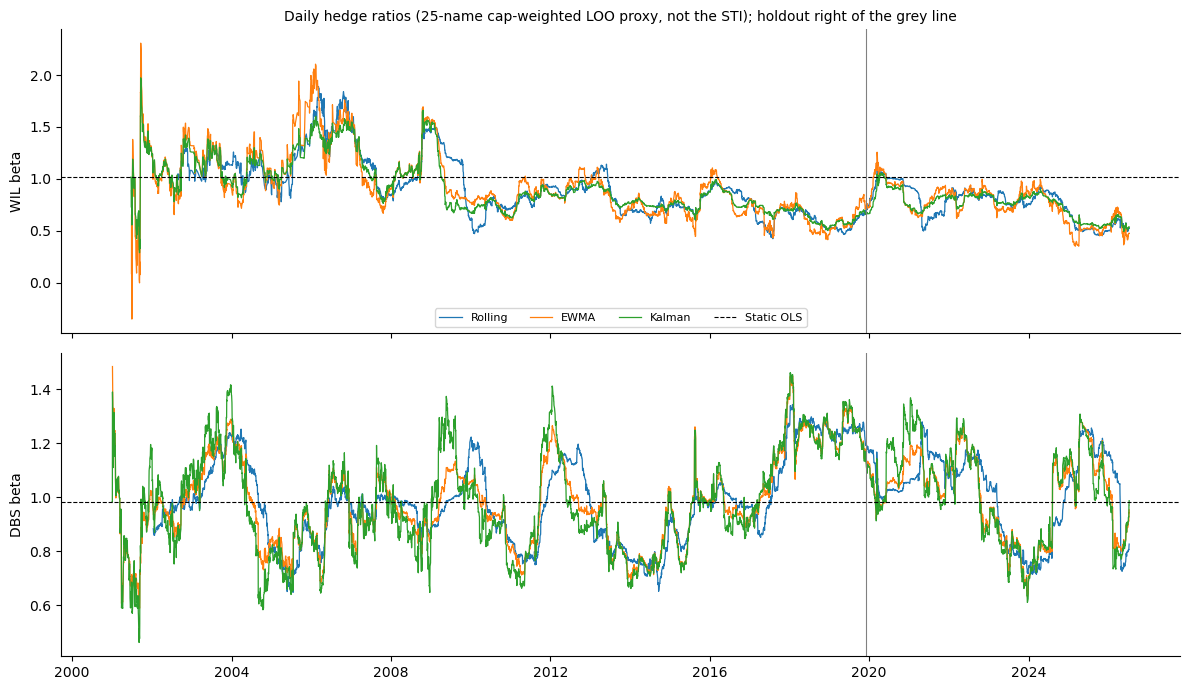

In [5]:
tr, proxy, _, _ = load_compustat('daily')
tr, proxy = tr[tr.index >= '2001-01-01'], proxy[proxy.index >= '2001-01-01']
ret = tr.pct_change(fill_method=None)
_, paths = kh.beta_hedge_test(ret[['WIL', 'DBS']], proxy, 'daily')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, name in zip(axes, ['WIL', 'DBS']):
    b = paths[name]
    for m in ['Rolling', 'EWMA', 'Kalman']:
        ax.plot(b.index, b[m], lw=0.9, label=m)
    ax.axhline(b['Static OLS'].iloc[0], color='k', lw=0.8, ls='--', label='Static OLS')
    ax.axvline(pd.Timestamp(kh.TEST_START), color='grey', lw=0.8)
    ax.set_ylabel(f'{name} beta')
axes[0].legend(ncol=4, fontsize=8); axes[0].set_title(f'Daily hedge ratios ({PROXY_LABEL}); holdout right of the grey line', fontsize=10)
fig.tight_layout(); fig.savefig(RES / 'fig_beta_paths_wil_dbs.png'); plt.show()

## Pairs: holdout cumulative return by method (daily)

Equal-weight across the daily pairs, net of 30 bp one-way per leg, one panel per entry
threshold. The daily run has 13 pairs: FLT clears the 756-day training minimum on daily data
but not the 60-month minimum, so its three pairs are in the daily run only.

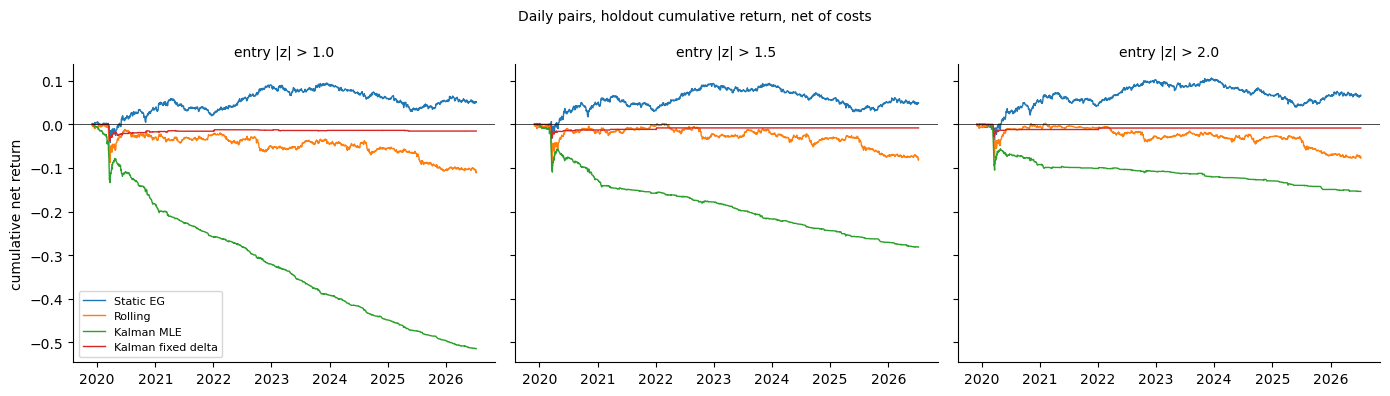

In [6]:
pairs, series, diag = kh.pairs_test(tr, 'daily')
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, k in zip(axes, (1.0, 1.5, 2.0)):
    for m in ['Static EG', 'Rolling', 'Kalman MLE', 'Kalman fixed delta']:
        port = pd.concat([v for (p, mm, kk), v in series.items() if mm == m and kk == k], axis=1).mean(axis=1)
        port = port[port.index >= kh.TEST_START]
        ax.plot(port.index, (1 + port).cumprod() - 1, lw=1, label=m)
    ax.axhline(0, color='k', lw=0.5); ax.set_title(f'entry |z| > {k}', fontsize=10)
axes[0].set_ylabel('cumulative net return'); axes[0].legend(fontsize=8)
fig.suptitle('Daily pairs, holdout cumulative return, net of costs', fontsize=10)
fig.tight_layout(); fig.savefig(RES / 'fig_pairs_holdout.png'); plt.show()

In [7]:
port = pd.read_csv(RES / 'pairs_portfolio_daily_25_proxy.csv')
port[port.period == 'oos'].pivot_table(index='method', columns='entry', values='t_nw')

entry,1.0,1.5,2.0
method,,,
Kalman MLE,-7.4536,-3.7744,-1.9295
Kalman fixed delta,-0.4547,-0.3265,-0.3905
Rolling,-1.2656,-0.9885,-1.0401
Static EG,0.8033,0.8266,1.0644


In [8]:
diag = pd.read_csv(RES / 'pair_diagnostics_daily_25_proxy.csv')
diag[['pair', 'cluster', 'eg_pvalue', 'half_life', 'kalman_mle_beta_oos_sd', 'kalman_fixed_beta_oos_sd']]  # half-life in trading days

,pair,cluster,eg_pvalue,half_life,kalman_mle_beta_oos_sd,kalman_fixed_beta_oos_sd
0,DBS/OCBC,Banks,1.8777e-01,192.9083,0.0157,0.0204
1,DBS/UOB,Banks,7.8258e-03,107.2635,0.0051,0.0300
2,OCBC/UOB,Banks,3.1189e-02,52.7191,0.0063,0.0223
3,CLAR/FLT,Industrial REITs,1.3206e-02,6.6643,0.0717,0.0772
4,CLAR/MINT,Industrial REITs,2.1459e-05,15.6663,0.0743,0.0665
5,CLAR/MLT,Industrial REITs,4.2747e-02,29.5916,0.0464,0.0371
6,FLT/MINT,Industrial REITs,1.4767e-01,7.1638,0.1117,0.1142
7,FLT/MLT,Industrial REITs,4.6059e-05,4.3277,0.0998,0.1102
8,MINT/MLT,Industrial REITs,6.3917e-01,82.8901,0.0346,0.0411
9,CICT/FCT,Retail/Div REITs,6.0715e-01,43.3210,0.0175,0.0436
